# ThreatLens — Task 3: State-Space Search

**Objective:** Model the ThreatLens cyber-threat decision workflow as a state space and implement **BFS, DFS, and A\***. Compare their solution paths by path cost, execution time, complexity, and optimality.

> This notebook is designed for **Google Colab** and is self-contained. It uses a small, explainable ThreatLens workflow graph rather than requiring the Kaggle CSV to run Task 3.

## 1. Problem statement and state-space model

ThreatLens receives a security log and processes it through parsing, validation, rule-based detection, ML/DL analysis, explanation, and report generation.

### State
A state represents the current stage of processing one uploaded security log:
- `START`
- `LOG_PARSED`
- `LOG_VALIDATED`
- `RULE_CHECKED`
- `ML_PREDICTED`
- `DL_PREDICTED`
- `EXPLANATION_GENERATED`
- `REPORT_GENERATED`
- `GOAL`

### Initial state
`START` — a security log has been uploaded and investigation has not yet completed.

### Goal state
`GOAL` — a final threat decision/report is available.

### Actions
An action moves the investigation from one stage to another, e.g.:
- parse log
- validate log
- apply rules
- run ML prediction
- run DL prediction
- generate explanation
- generate report

### State transition
`current_state --action/cost--> next_state`

The edge cost represents relative computational/processing effort for that transition. Lower cost is preferred.

### Search objective
Find a valid path from `START` to `GOAL`. We compare:
- **BFS:** minimum number of transitions (optimal only when every step has equal cost)
- **DFS:** first goal found using depth-first traversal (not guaranteed optimal)
- **A\*:** minimizes `f(n)=g(n)+h(n)` when `h(n)` is admissible/consistent.

In [ ]:
# Imports
from collections import deque
import heapq
import time
import pandas as pd
import matplotlib.pyplot as plt

print("ThreatLens Task 3 environment ready.")

ThreatLens Task 3 environment ready.


In [ ]:
# 2. Define the ThreatLens state space
# graph[state] = [(next_state, action, cost), ...]

graph = {
    "START": [
        ("LOG_PARSED", "Parse log", 1),
        ("LOG_VALIDATED", "Validate log", 2),
    ],
    "LOG_PARSED": [
        ("ML_PREDICTED", "Run ML prediction", 1),
        ("RULE_CHECKED", "Apply rule base", 5),
    ],
    "LOG_VALIDATED": [
        ("RULE_CHECKED", "Apply rule base", 1),
    ],
    "RULE_CHECKED": [
        ("ML_PREDICTED", "Run ML prediction", 1),
    ],
    "ML_PREDICTED": [
        ("EXPLANATION_GENERATED", "Generate explanation", 5),
        ("DL_PREDICTED", "Run LSTM/DL prediction", 1),
    ],
    "DL_PREDICTED": [
        ("EXPLANATION_GENERATED", "Generate explanation", 1),
    ],
    "EXPLANATION_GENERATED": [
        ("REPORT_GENERATED", "Generate report", 1),
    ],
    "REPORT_GENERATED": [
        ("GOAL", "Finalize threat report", 1),
    ],
    "GOAL": []
}

START = "START"
GOAL = "GOAL"

print("States:", len(graph))
print("Initial state:", START)
print("Goal state:", GOAL)

States: 9
Initial state: START
Goal state: GOAL


In [ ]:
# Display transitions as a table
rows = []
for src, edges in graph.items():
    for dst, action, cost in edges:
        rows.append([src, action, dst, cost])

transitions_df = pd.DataFrame(rows, columns=["From", "Action", "To", "Cost"])
transitions_df

,From,Action,To,Cost
0,START,Parse log,LOG_PARSED,1
1,START,Validate log,LOG_VALIDATED,2
2,LOG_PARSED,Run ML prediction,ML_PREDICTED,1
3,LOG_PARSED,Apply rule base,RULE_CHECKED,5
4,LOG_VALIDATED,Apply rule base,RULE_CHECKED,1
5,RULE_CHECKED,Run ML prediction,ML_PREDICTED,1
6,ML_PREDICTED,Generate explanation,EXPLANATION_GENERATED,5
7,ML_PREDICTED,Run LSTM/DL prediction,DL_PREDICTED,1
8,DL_PREDICTED,Generate explanation,EXPLANATION_GENERATED,1
9,EXPLANATION_GENERATED,Generate report,REPORT_GENERATED,1


## 3. Visualize the state space

The graph intentionally contains:
- a **shorter but expensive** route: `START → LOG_PARSED → ML_PREDICTED → EXPLANATION_GENERATED → REPORT_GENERATED → GOAL`
- a **longer but cheaper** route through validation, rules, ML and DL.

This makes the difference between BFS and cost-aware A\* visible.

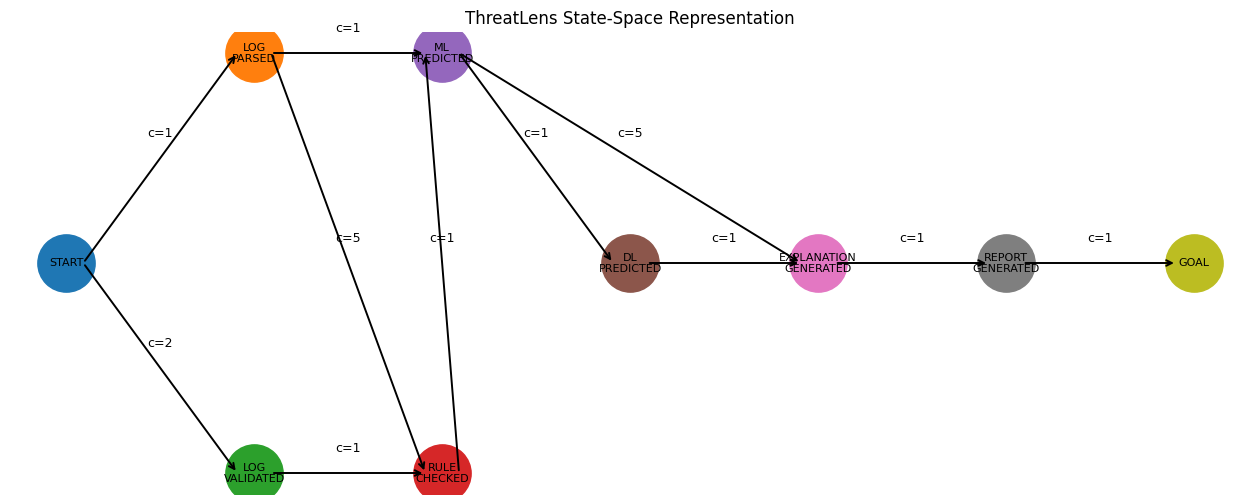

In [ ]:
# Draw a simple directed state-space diagram
positions = {
    "START": (0, 2),
    "LOG_PARSED": (2, 3),
    "LOG_VALIDATED": (2, 1),
    "RULE_CHECKED": (4, 1),
    "ML_PREDICTED": (4, 3),
    "DL_PREDICTED": (6, 2),
    "EXPLANATION_GENERATED": (8, 2),
    "REPORT_GENERATED": (10, 2),
    "GOAL": (12, 2),
}

plt.figure(figsize=(16, 6))
for src, edges in graph.items():
    x1, y1 = positions[src]
    for dst, action, cost in edges:
        x2, y2 = positions[dst]
        plt.annotate("", xy=(x2-0.18, y2), xytext=(x1+0.18, y1),
                     arrowprops=dict(arrowstyle="->", lw=1.4))
        mx, my = (x1+x2)/2, (y1+y2)/2
        plt.text(mx, my+0.10, f"c={cost}", fontsize=9, ha="center")

for state, (x, y) in positions.items():
    plt.scatter(x, y, s=1700)
    plt.text(x, y, state.replace("_", "\n"), ha="center", va="center", fontsize=8)

plt.axis("off")
plt.title("ThreatLens State-Space Representation")
plt.show()

## 4. Breadth-First Search (BFS)

BFS explores states level by level. Therefore it returns a path with the **fewest transitions**.

**Completeness:** Yes for a finite branching factor.

**Optimality:** Only when all edge costs are equal. Here costs differ, so BFS is not guaranteed to minimize total processing cost.

In [ ]:
def reconstruct_path(parent, goal):
    path = []
    cur = goal
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    return path[::-1]

def path_cost(path, graph):
    total = 0
    actions = []
    for a, b in zip(path, path[1:]):
        for dst, action, cost in graph[a]:
            if dst == b:
                total += cost
                actions.append((action, cost))
                break
    return total, actions

def bfs(graph, start, goal):
    q = deque([start])
    parent = {start: None}
    expanded = 0

    while q:
        node = q.popleft()
        expanded += 1
        if node == goal:
            return reconstruct_path(parent, goal), expanded

        for nxt, action, cost in graph[node]:
            if nxt not in parent:
                parent[nxt] = node
                q.append(nxt)
    return None, expanded

bfs_path, bfs_expanded = bfs(graph, START, GOAL)
bfs_cost, bfs_actions = path_cost(bfs_path, graph)

print("BFS path:", " -> ".join(bfs_path))
print("BFS path cost:", bfs_cost)
print("BFS transitions:", len(bfs_path)-1)
print("BFS expanded states:", bfs_expanded)

BFS path: START -> LOG_PARSED -> ML_PREDICTED -> EXPLANATION_GENERATED -> REPORT_GENERATED -> GOAL
BFS path cost: 9
BFS transitions: 5
BFS expanded states: 9


## 5. Depth-First Search (DFS)

DFS follows one branch as deeply as possible before backtracking.

**Completeness:** Yes on this finite graph when visited-state checking is used.

**Optimality:** No. DFS returns the first goal it encounters and may choose a more expensive path.

In [ ]:
def dfs(graph, start, goal):
    stack = [start]
    parent = {start: None}
    expanded = 0

    while stack:
        node = stack.pop()
        expanded += 1
        if node == goal:
            return reconstruct_path(parent, goal), expanded

        # Reverse insertion keeps the displayed order deterministic.
        for nxt, action, cost in reversed(graph[node]):
            if nxt not in parent:
                parent[nxt] = node
                stack.append(nxt)
    return None, expanded

dfs_path, dfs_expanded = dfs(graph, START, GOAL)
dfs_cost, dfs_actions = path_cost(dfs_path, graph)

print("DFS path:", " -> ".join(dfs_path))
print("DFS path cost:", dfs_cost)
print("DFS transitions:", len(dfs_path)-1)
print("DFS expanded states:", dfs_expanded)

DFS path: START -> LOG_PARSED -> ML_PREDICTED -> EXPLANATION_GENERATED -> REPORT_GENERATED -> GOAL
DFS path cost: 9
DFS transitions: 5
DFS expanded states: 6


## 6. A* Search

A\* uses:

`f(n) = g(n) + h(n)`

where:
- `g(n)` = cost accumulated from `START` to `n`
- `h(n)` = estimated remaining cost from `n` to `GOAL`

### Heuristic

For this workflow, we use an admissible heuristic equal to the **minimum unavoidable number of remaining workflow stages**, with each remaining stage costing at least 1.

Therefore the heuristic never overestimates the actual remaining cost. It is also consistent for the unit lower-bound used here.

This makes A\* optimal for the defined edge costs.

In [ ]:
# Admissible heuristic: minimum number of transitions remaining.
# It never exceeds the true remaining cost because every edge has cost >= 1.

heuristic = {
    "START": 4,
    "LOG_PARSED": 3,
    "LOG_VALIDATED": 4,
    "RULE_CHECKED": 3,
    "ML_PREDICTED": 2,
    "DL_PREDICTED": 1,
    "EXPLANATION_GENERATED": 1,
    "REPORT_GENERATED": 1,
    "GOAL": 0,
}

def astar(graph, start, goal, h):
    pq = [(h[start], 0, start)]
    best_g = {start: 0}
    parent = {start: None}
    expanded = 0

    while pq:
        f, g, node = heapq.heappop(pq)

        if g != best_g.get(node):
            continue

        expanded += 1
        if node == goal:
            return reconstruct_path(parent, goal), expanded

        for nxt, action, cost in graph[node]:
            new_g = g + cost
            if new_g < best_g.get(nxt, float("inf")):
                best_g[nxt] = new_g
                parent[nxt] = node
                heapq.heappush(pq, (new_g + h[nxt], new_g, nxt))

    return None, expanded

astar_path, astar_expanded = astar(graph, START, GOAL, heuristic)
astar_cost, astar_actions = path_cost(astar_path, graph)

print("A* path:", " -> ".join(astar_path))
print("A* path cost:", astar_cost)
print("A* transitions:", len(astar_path)-1)
print("A* expanded states:", astar_expanded)

A* path: START -> LOG_PARSED -> ML_PREDICTED -> DL_PREDICTED -> EXPLANATION_GENERATED -> REPORT_GENERATED -> GOAL
A* path cost: 6
A* transitions: 6
A* expanded states: 9


In [ ]:
# 7. Compare BFS, DFS and A*
def benchmark(search_fn, repeats=2000):
    total = 0.0
    result = None
    expanded = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        result, expanded = search_fn()
        total += time.perf_counter() - t0
    return result, expanded, total / repeats * 1000

bfs_p, bfs_e, bfs_ms = benchmark(lambda: bfs(graph, START, GOAL))
dfs_p, dfs_e, dfs_ms = benchmark(lambda: dfs(graph, START, GOAL))
astar_p, astar_e, astar_ms = benchmark(lambda: astar(graph, START, GOAL, heuristic))

bfs_c, _ = path_cost(bfs_p, graph)
dfs_c, _ = path_cost(dfs_p, graph)
astar_c, _ = path_cost(astar_p, graph)

comparison = pd.DataFrame([
    ["BFS", " -> ".join(bfs_p), bfs_c, len(bfs_p)-1, bfs_e, bfs_ms, "Optimal in number of edges; NOT cost-optimal here"],
    ["DFS", " -> ".join(dfs_p), dfs_c, len(dfs_p)-1, dfs_e, dfs_ms, "Not guaranteed optimal"],
    ["A*", " -> ".join(astar_p), astar_c, len(astar_p)-1, astar_e, astar_ms, "Cost-optimal with admissible heuristic"],
], columns=["Algorithm", "Solution path", "Path cost", "Transitions", "Expanded states", "Avg time (ms)", "Optimality"])

comparison

,Algorithm,Solution path,Path cost,Transitions,Expanded states,Avg time (ms),Optimality
0,BFS,START -> LOG_PARSED -> ML_PREDICTED -> EXPLANA...,9,5,9,0.003315,Optimal in number of edges; NOT cost-optimal here
1,DFS,START -> LOG_PARSED -> ML_PREDICTED -> EXPLANA...,9,5,6,0.002923,Not guaranteed optimal
2,A*,START -> LOG_PARSED -> ML_PREDICTED -> DL_PRED...,6,6,9,0.007938,Cost-optimal with admissible heuristic


## 8. Complexity and interpretation

Let `b` be the branching factor and `d` the depth of the shallowest solution.

| Algorithm | Time complexity | Space complexity | Optimality |
|---|---|---|---|
| BFS | O(b^d) | O(b^d) | Yes for equal edge costs |
| DFS | O(b^m) | O(bm) | No |
| A* | O(b^d) worst case | O(b^d) | Yes with an admissible heuristic |

`m` is the maximum search depth.

For this ThreatLens graph:
- **BFS** chooses the path with fewer transitions, but can pay higher processing cost.
- **DFS** can reach the goal quickly in terms of traversal depth but has no cost-optimality guarantee.
- **A\*** considers accumulated cost plus the heuristic and therefore selects the lowest-cost solution under the defined model.

Execution times are hardware/interpreter dependent, so the **path cost and optimality properties are the meaningful comparison**, while measured runtime is included as an empirical observation.

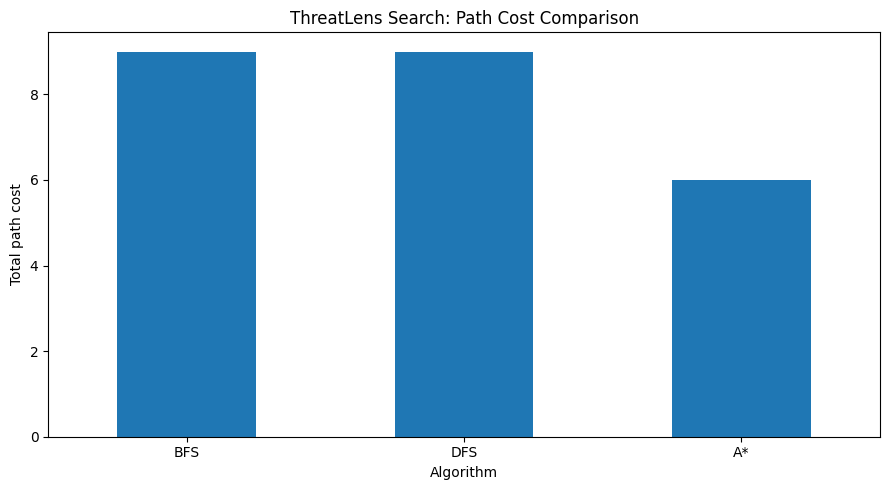

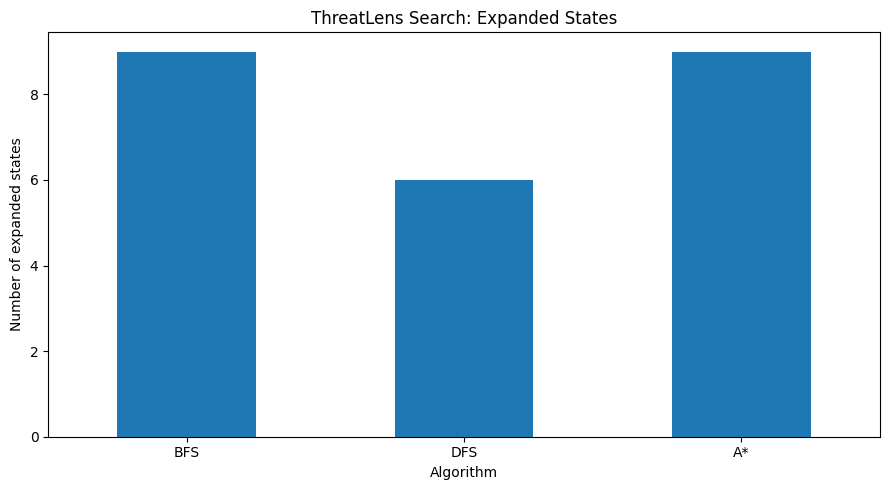

In [ ]:
# 9. Visual comparison
fig, ax = plt.subplots(figsize=(9, 5))
comparison.plot(x="Algorithm", y="Path cost", kind="bar", legend=False, ax=ax)
ax.set_ylabel("Total path cost")
ax.set_title("ThreatLens Search: Path Cost Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
comparison.plot(x="Algorithm", y="Expanded states", kind="bar", legend=False, ax=ax)
ax.set_ylabel("Number of expanded states")
ax.set_title("ThreatLens Search: Expanded States")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Final conclusion for Task 3

The ThreatLens security-log investigation can be represented as a state-space problem in which each processing stage is a state and each cybersecurity analysis operation is an action.

**Result:**
1. **BFS** finds the shallowest solution, but because transition costs differ, its path is not necessarily the cheapest.
2. **DFS** can find a valid solution without considering total cost, so it is not guaranteed optimal.
3. **A\*** combines actual cost `g(n)` with the admissible heuristic `h(n)` and obtains the **minimum-cost solution** for this model.

### Report-ready conclusion
> A state-space model was successfully constructed for the ThreatLens decision-support workflow. BFS, DFS and A* were implemented and tested on the same state graph. BFS was evaluated for minimum-depth search, DFS for depth-first exploration, and A* for cost-aware optimal search. The comparison demonstrates why heuristic search is suitable when cybersecurity processing actions have different costs. A* produced the cost-optimal path under the defined admissible heuristic, while BFS optimized the number of transitions and DFS provided no optimality guarantee.